# Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder for exported charts
OUTPUT_DIR = Path("charts")
OUTPUT_DIR.mkdir(exist_ok=True)

# Presentation-friendly default settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11
plt.rcParams["legend.fontsize"] = 11
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"


## Harmonization numbers

In [2]:
COLLECTED_VALID_IMAGES = 45011
HARMONIZED_AFTER_DOWNSAMPLING = 29849
EXCLUDED_IMAGES = 15486

label_distribution = pd.DataFrame({
    "label": ["cardboard", "glass", "metal", "paper", "plastic", "trash"],
    "count": [4849, 5000, 5000, 5000, 5000, 5000],
})

downsampling_summary = pd.DataFrame({
    "label": ["cardboard", "glass", "metal", "paper", "plastic", "trash"],
    "original": [4849, 5748, 5379, 8252, 10480, 10303],
    "kept": [4849, 5000, 5000, 5000, 5000, 5000],
    "removed": [0, 748, 379, 3252, 5480, 5303],
})

source_distribution = pd.DataFrame({
    "source_dataset": ["garbage_dataset", "household_garbage", "trashnet", "tricascade"],
    "count": [5476, 10665, 1734, 11974],
})

display(label_distribution)
display(downsampling_summary)
display(source_distribution)


,label,count
0,cardboard,4849
1,glass,5000
2,metal,5000
3,paper,5000
4,plastic,5000
5,trash,5000


,label,original,kept,removed
0,cardboard,4849,4849,0
1,glass,5748,5000,748
2,metal,5379,5000,379
3,paper,8252,5000,3252
4,plastic,10480,5000,5480
5,trash,10303,5000,5303


,source_dataset,count
0,garbage_dataset,5476
1,household_garbage,10665
2,trashnet,1734
3,tricascade,11974


## final label distribution

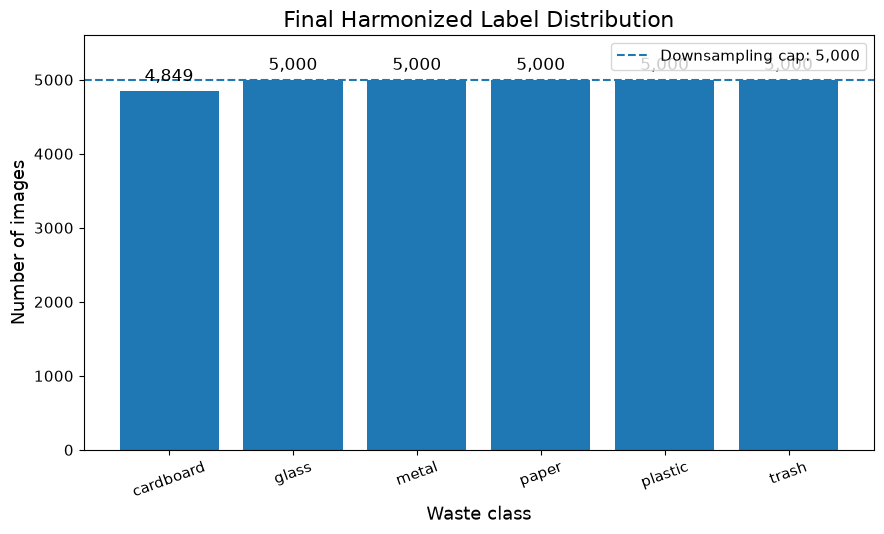

In [3]:
df = label_distribution.copy()

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(df["label"], df["count"])

ax.axhline(5000, linestyle="--", linewidth=1.5, label="Downsampling cap: 5,000")
ax.set_title("Final Harmonized Label Distribution")
ax.set_xlabel("Waste class")
ax.set_ylabel("Number of images")
ax.set_ylim(0, 5600)
ax.legend()

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 80,
        f"{int(height):,}",
        ha="center",
        va="bottom",
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_label_distribution.png")
plt.savefig(OUTPUT_DIR / "01_label_distribution.svg")
plt.show()


## downsampling

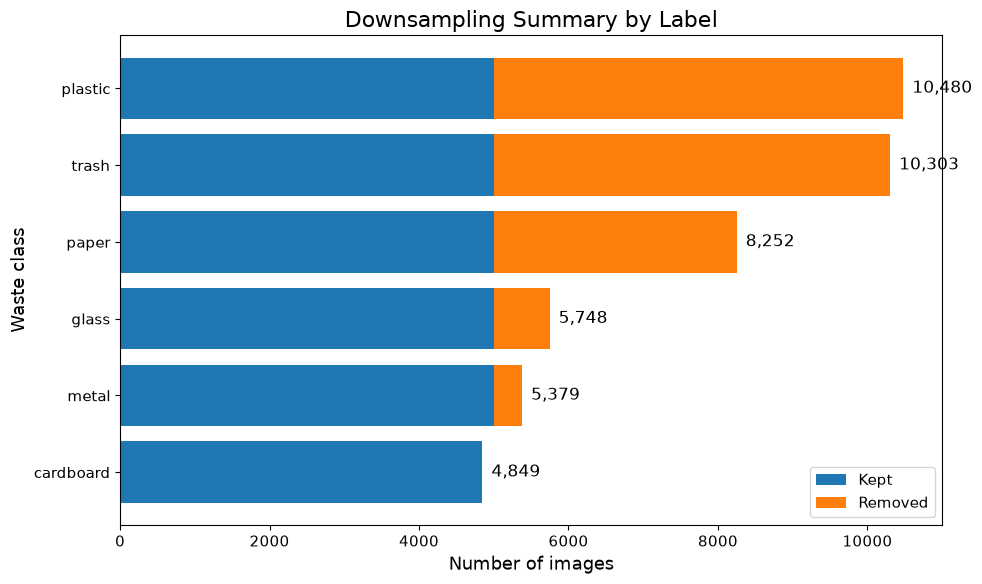

In [4]:
df = downsampling_summary.sort_values("original", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(df["label"], df["kept"], label="Kept")
ax.barh(df["label"], df["removed"], left=df["kept"], label="Removed")

ax.set_title("Downsampling Summary by Label")
ax.set_xlabel("Number of images")
ax.set_ylabel("Waste class")
ax.legend()

for _, row in df.iterrows():
    ax.text(row["original"] + 120, row["label"], f"{row['original']:,}", va="center")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_downsampling_summary.png")
plt.savefig(OUTPUT_DIR / "02_downsampling_summary.svg")
plt.show()


## source dataset distribution

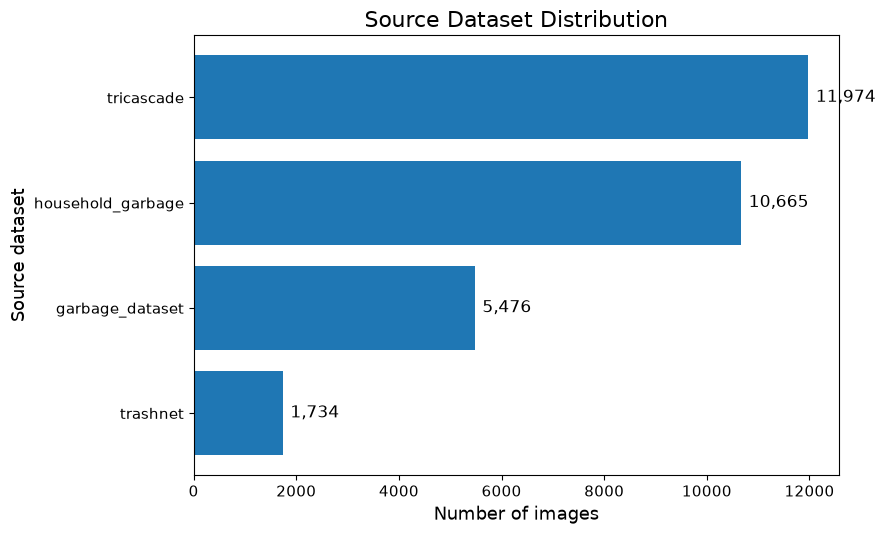

In [5]:
df = source_distribution.sort_values("count", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(df["source_dataset"], df["count"])

ax.set_title("Source Dataset Distribution")
ax.set_xlabel("Number of images")
ax.set_ylabel("Source dataset")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 150, bar.get_y() + bar.get_height() / 2, f"{int(width):,}", va="center")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_source_dataset_distribution.png")
plt.savefig(OUTPUT_DIR / "03_source_dataset_distribution.svg")
plt.show()


## source dataset share

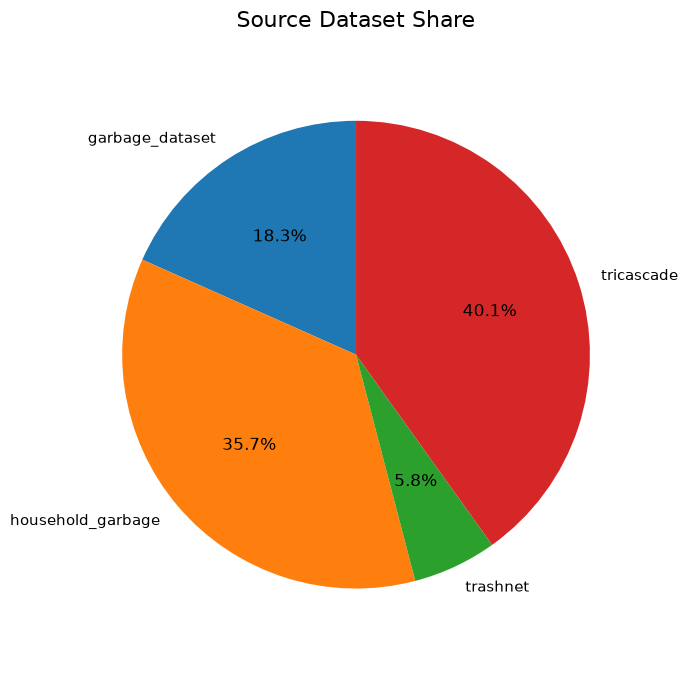

In [6]:
df = source_distribution.copy()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    df["count"],
    labels=df["source_dataset"],
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title("Source Dataset Share")
ax.axis("equal")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_source_dataset_share.png")
plt.savefig(OUTPUT_DIR / "04_source_dataset_share.svg")
plt.show()


## Pipeline overview numbers

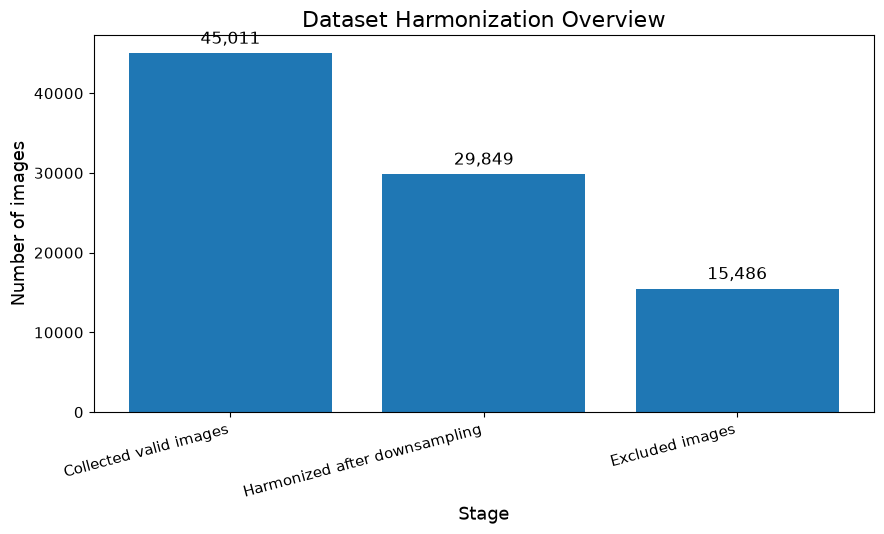

In [7]:
pipeline_counts = pd.DataFrame({
    "stage": ["Collected valid images", "Harmonized after downsampling", "Excluded images"],
    "count": [COLLECTED_VALID_IMAGES, HARMONIZED_AFTER_DOWNSAMPLING, EXCLUDED_IMAGES],
})

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(pipeline_counts["stage"], pipeline_counts["count"])

ax.set_title("Dataset Harmonization Overview")
ax.set_xlabel("Stage")
ax.set_ylabel("Number of images")

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 700,
        f"{int(height):,}",
        ha="center",
        va="bottom",
    )

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_harmonization_overview.png")
plt.savefig(OUTPUT_DIR / "05_harmonization_overview.svg")
plt.show()


## contribution per label


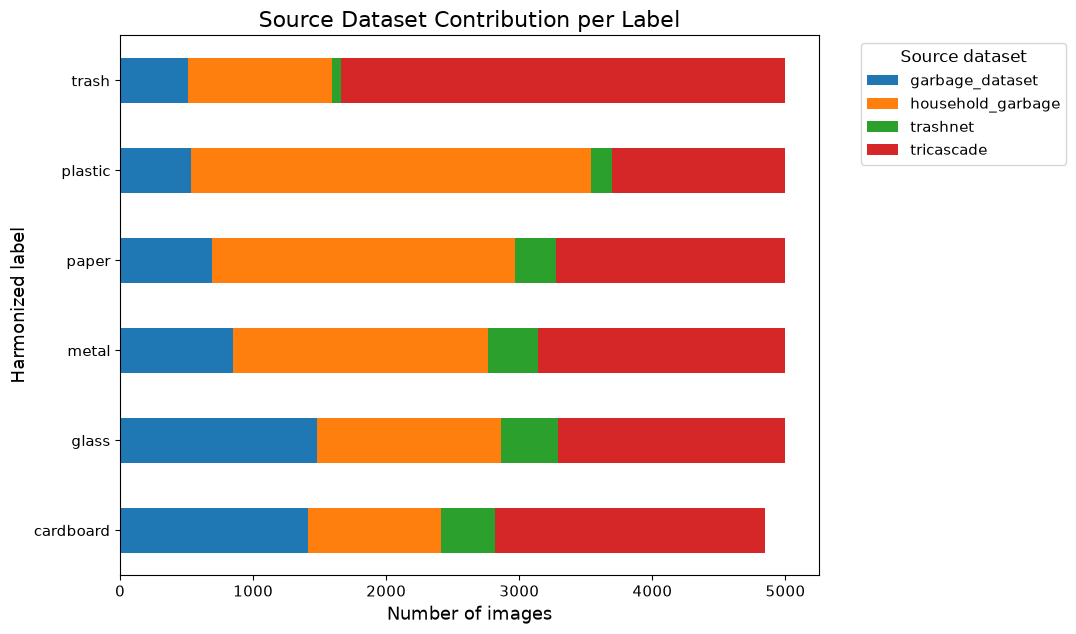

In [10]:
# Optional: run after loading hf_df in the previous section

source_by_label = (
    hf_df.groupby([label_col, source_col])
    .size()
    .reset_index(name="count")
)

pivot = source_by_label.pivot(
    index=label_col,
    columns=source_col,
    values="count",
).fillna(0)

pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=True).index]

ax = pivot.plot(kind="barh", stacked=True, figsize=(11, 6.5))
ax.set_title("Source Dataset Contribution per Label")
ax.set_xlabel("Number of images")
ax.set_ylabel("Harmonized label")
ax.legend(title="Source dataset", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_source_contribution_per_label.png")
plt.savefig(OUTPUT_DIR / "06_source_contribution_per_label.svg")
plt.show()
